# How long would it take on the device?

Every job carries a hardware-time estimate from an as-soon-as-possible schedule built with each device's gate durations
and parallelism limits. The values are estimates: durations are published for the IBM and Google twins and mostly assumed
for the others (notebook 01 lists which).

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': 'c88add07efb8:7:a77a42',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. Time per shot on every twin

A 10-qubit GHZ takes microseconds on superconducting twins and milliseconds on trapped ions.

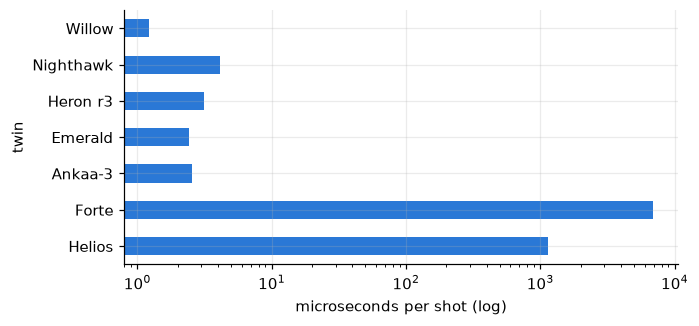

,us per shot
twin,
Helios,1150.000
Forte,6915.000
Ankaa-3,2.548
Emerald,2.440
Heron r3,3.132
Nighthawk,4.132
Willow,1.228


In [2]:
rows = []
for b in ALL_BACKENDS:
    h = run(b, ghz(10), shots=1000, routing=True)["compilation"]["hardware_time_estimate"]
    rows.append({"twin": NAMES[b], "us per shot": h["circuit_duration_us"]})
t = pd.DataFrame(rows).set_index("twin")
t.plot.barh(logx=True, legend=False, figsize=(6.5, 3), color=[COLORS[b] for b in ALL_BACKENDS])
plt.xlabel("microseconds per shot (log)"); plt.show()
t

## 2. Job duration and per-shot overhead

The job estimate multiplies by the shot count. IBM publishes a repetition delay between shots, which dominates its estimate; for the other twins the per-shot overhead is unpublished and left out, as the response states.

In [3]:
rows = []
for b in ALL_BACKENDS:
    h = run(b, ghz(5), shots=1000, routing=True)["compilation"]["hardware_time_estimate"]
    rows.append({"twin": NAMES[b], "circuit us": h["circuit_duration_us"], "overhead us per shot": h["shot_overhead_us"],
                 "1000 shots (s)": h["estimated_job_duration_s"], "includes overhead": h["includes_shot_overhead"]})
pd.DataFrame(rows).set_index("twin")

,circuit us,overhead us per shot,1000 shots (s),includes overhead
twin,,,,
Helios,600.000,NaN,0.600000,False
Forte,3240.000,NaN,3.240000,False
Ankaa-3,1.988,NaN,0.001988,False
Emerald,1.940,NaN,0.001940,False
Heron r3,2.632,250.0,0.252632,True
Nighthawk,3.232,4000.0,4.003232,True
Willow,0.893,NaN,0.000893,False


## 3. Parallel gates

Four independent CX pairs can run at once on most devices. IonQ Forte runs one entangling gate at a time in its single ion chain, so its time grows with the number of pairs.

In [4]:
rows = []
for pairs in (1, 2, 4, 8):
    prog = program(2 * pairs, [f"cx q[{2 * i}],q[{2 * i + 1}]" for i in range(pairs)])
    row = {"parallel CX pairs": pairs}
    for b in ("quantinuum_helios", "ionq_forte", "iqm_emerald", "ibm_heron"):
        row[NAMES[b]] = run(b, prog, shots=10, routing=True)["compilation"]["hardware_time_estimate"]["circuit_duration_us"]
    rows.append(row)
pd.DataFrame(rows).set_index("parallel CX pairs")

,Helios,Forte,Emerald,Heron r3
parallel CX pairs,,,,
1,270.0,1170.0,1.64,2.332
2,270.0,1770.0,1.64,2.332
4,270.0,2970.0,1.64,2.332
8,270.0,5370.0,1.64,2.332


## 4. Where the time goes

The busy time per operation class, summed over qubits, shows that readout dominates a short superconducting circuit.

In [5]:
rows = []
for b in ALL_BACKENDS:
    busy = run(b, ghz(6), shots=10, routing=True)["compilation"]["hardware_time_estimate"]["busy_time_us"]
    rows.append({"twin": NAMES[b], **busy})
pd.DataFrame(rows).set_index("twin").round(3)

,one_qubit,two_qubit,measure,reset,transport
twin,,,,,
Helios,110.000,500.00,900.0,0.0,0.0
Forte,1350.000,3000.00,1800.0,0.0,0.0
Ankaa-3,0.440,0.36,9.0,0.0,0.0
Emerald,0.440,0.30,9.0,0.0,0.0
Heron r3,0.352,0.34,13.2,0.0,0.0
Nighthawk,0.352,1.08,14.4,0.0,0.0
Willow,0.275,0.21,3.6,0.0,0.0


## 5. A shallower circuit is a faster circuit

A GHZ state can be prepared with a chain (depth n) or a tree that doubles the entangled set each step (depth log₂ n). On devices that run gates in parallel, the tree is much faster.

In [6]:
def ghz_tree(n):
    lines, have = ["h q[0]"], 1
    while have < n:
        lines += [f"cx q[{i}],q[{i + have}]" for i in range(have) if i + have < n]
        have *= 2
    return program(n, lines)

rows = []
for b in ("quantinuum_helios", "ionq_forte", "iqm_emerald", "google_willow"):
    chain = run(b, ghz(8), shots=10, routing=True)["compilation"]
    tree = run(b, ghz_tree(8), shots=10, routing=True)["compilation"]
    rows.append({"twin": NAMES[b], "chain us": chain["hardware_time_estimate"]["circuit_duration_us"],
                 "tree us": tree["hardware_time_estimate"]["circuit_duration_us"],
                 "chain 2Q depth": chain["two_qubit_depth"], "tree 2Q depth": tree["two_qubit_depth"]})
pd.DataFrame(rows).set_index("twin")

,chain us,tree us,chain 2Q depth,tree 2Q depth
twin,,,,
Helios,930.000,490.000,7,3
Forte,5445.000,4770.000,7,3
Emerald,2.240,1.840,7,3
Willow,1.094,0.826,7,3


## Takeaways

- Superconducting shots take microseconds and trapped-ion shots milliseconds, three orders of magnitude apart.
- Parallelism limits and per-shot overheads matter as much as gate times.